# TP2: Odd or Even? A Deep Network from Scratch

**Deadline:** 9/11/2026. **Submit:** `TP2_Name_StudentID_group.ipynb` for example `TP2_Your_name_I4_AMSB.ipynb` by github

**The task.** Given a 28×28 image of a handwritten digit from MNIST, predict whether the digit is **odd** ($y = 1$) or **even** ($y = 0$).

This is a good test for depth. Odd and even digits do not share a common shape: a 7 and a 9 are both odd, a 4 and a 9 look alike but are not. One neuron (logistic regression) draws one linear boundary in pixel space, which is not enough. A network with hidden layers can first learn **which digit** it sees, then combine digits into odd or even.

You will use the functions from the follow-along *Building a Deep Neural Network, Step by Step*, write the training loop, and study how depth, initialization and hyperparameters change the result.


## Part 0 · Setup

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.11.0+cpu


## Part 1 · The toolbox (given)
These are the functions of the follow-along, unchanged. Run the cell; **do not modify it.** Examples are rows: $\mathbf{X}$ has shape $(m, 784)$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$.

In [2]:
# From the follow-along "Building a Deep Neural Network, Step by Step". Do not modify.

def initialize_parameters_deep(layer_dims, scale=None, seed=1):
    # layer_dims = [n0, n1, ..., nL]. W_l has shape (n_{l-1}, n_l), b_l has shape (1, n_l).
    # scale=None uses sqrt(1 / n_{l-1}); a number (e.g. 0.01) uses that number for every layer.
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        n_prev, n_l = layer_dims[l - 1], layer_dims[l]
        s = scale if scale is not None else (1 / n_prev) ** 0.5
        params[f"W{l}"] = torch.randn(n_prev, n_l) * s
        params[f"b{l}"] = torch.zeros(1, n_l)
    return params

def linear_forward(A_prev, W, b):
    # Z = A_prev W + b. The cache keeps what the backward pass will need.
    Z = A_prev @ W + b
    cache = (A_prev, W, b)
    return Z, cache

def sigmoid(Z):
    return torch.sigmoid(Z), Z          # (A, cache); the cache is Z

def relu(Z):
    return torch.clamp(Z, min=0), Z     # max(0, Z), elementwise

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    return A, (linear_cache, activation_cache)

def L_model_forward(X, params):
    # [LINEAR -> RELU] x (L - 1), then LINEAR -> SIGMOID.
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, params[f"W{l}"], params[f"b{l}"], "relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, params[f"W{L}"], params[f"b{L}"], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples. AL and Y have shape (m, 1).
    AL = AL.clamp(eps, 1 - eps)        # avoids log(0)
    return -(Y * torch.log(AL) + (1 - Y) * torch.log(1 - AL)).mean()

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[0]                              # examples are rows
    dW = A_prev.T @ dZ / m                           # (n_prev, n_l)
    db = dZ.sum(dim=0, keepdim=True) / m             # (1, n_l)
    dA_prev = dZ @ W.T                               # (m, n_prev)
    return dA_prev, dW, db

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0).float()                      # g'(Z) = 1 where Z > 0, else 0

def sigmoid_backward(dA, cache):
    Z = cache
    s = torch.sigmoid(Z)
    return dA * s * (1 - s)                          # g'(Z) = s (1 - s)

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    return linear_backward(dZ, linear_cache)

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    # Output layer: sigmoid + cross-entropy together give dZ = AL - Y (Lecture 2).
    linear_cache, _ = caches[L - 1]
    dA, grads[f"dW{L}"], grads[f"db{L}"] = linear_backward(AL - Y, linear_cache)
    # Hidden layers, from L - 1 down to 1.
    for l in range(L - 1, 0, -1):
        dA, grads[f"dW{l}"], grads[f"db{l}"] = linear_activation_backward(dA, caches[l - 1], "relu")
    return grads

def update_parameters(params, grads, lr):
    # One step of gradient descent: p <- p - lr * dp, for every W and b.
    return {k: params[k] - lr * grads["d" + k] for k in params}

## Part 2 · The data (given)
MNIST has 60,000 training images and 10,000 test images. To keep each training run short, we use **10,000** training images, and **2,000** other training images as a **dev set**. The 10,000 test images are kept for the very end.

- **Training set:** used to learn the parameters.
- **Dev set:** used to **compare** models and choose hyperparameters.
- **Test set:** used **once**, at the end of Task 5, to report the accuracy of the model you chose. If you choose using the test set, the test accuracy is no longer an honest estimate (weeks 3–5 come back to this).

Each image is flattened into 784 values in $[0, 1]$. We keep the digit itself in `digits_*` for the error analysis.

100%|██████████| 9.91M/9.91M [00:00<00:00, 133MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 31.7MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 94.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.12MB/s]


train X (10000, 784) Y (10000, 1) fraction odd 0.521
dev   X (2000, 784)  Y (2000, 1)  fraction odd 0.512
test  X (10000, 784) Y (10000, 1) fraction odd 0.507


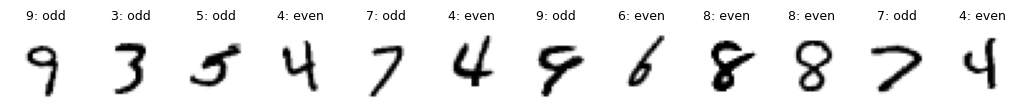

In [3]:
mnist_train = torchvision.datasets.MNIST(root="data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="data", train=False, download=True)

def make_odd_even(dataset, idx):
    X = dataset.data[idx].reshape(len(idx), -1).float() / 255
    digits = dataset.targets[idx]
    Y = (digits % 2 == 1).float().reshape(-1, 1)          # 1 = odd, 0 = even
    return X, Y, digits

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
X_train, Y_train, digits_train = make_odd_even(mnist_train, perm[:10000])
X_dev, Y_dev, digits_dev = make_odd_even(mnist_train, perm[10000:12000])
X_test, Y_test, digits_test = make_odd_even(mnist_test, torch.arange(10000))

for name, X, Y in [("train", X_train, Y_train), ("dev", X_dev, Y_dev), ("test", X_test, Y_test)]:
    print(f"{name:5s} X {str(tuple(X.shape)):12s} Y {str(tuple(Y.shape)):10s} fraction odd {Y.mean().item():.3f}")

fig, axes = plt.subplots(1, 12, figsize=(13, 1.6))
for ax, img, d in zip(axes, X_train[:12], digits_train[:12]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{d.item()}: {'odd' if d % 2 else 'even'}", fontsize=9); ax.axis("off")
plt.show()

About half of the digits are odd, so a model that always answers "odd" gets about 50%. That is the baseline to beat.

## Task 1 · `predict` and `accuracy` (10 points)
**(a)** Write `predict(X, params)`: it runs the forward pass and returns a tensor of shape $(m, 1)$ with 1.0 where $a^{[L]} > 0.5$ and 0.0 elsewhere.

**(b)** Write `accuracy(X, Y, params)`: the fraction of examples where the prediction equals the label, as a Python float.

**(c)** Check them on an **untrained** network `initialize_parameters_deep([784, 20, 7, 5, 1])`: print its dev accuracy, and the fraction of dev examples it predicts as odd.

Expected output:
```
untrained network | dev accuracy 0.576 | predicted odd 0.449
```

In [4]:
def predict(X, params):
    AL, _ = L_model_forward(X, params)
    return (AL > 0.5).float()          # shape (m, 1), 1.0 where a^[L] > 0.5

def accuracy(X, Y, params):
    preds = predict(X, params)
    return (preds == Y).float().mean().item()   # Python float

params0 = initialize_parameters_deep([784, 20, 7, 5, 1])

# (c) dev accuracy and fraction predicted odd on the untrained network
dev_acc = accuracy(X_dev, Y_dev, params0)
frac_odd = predict(X_dev, params0).mean().item()
print(f"untrained network | dev accuracy {dev_acc:.3f} | predicted odd {frac_odd:.3f}")

untrained network | dev accuracy 0.576 | predicted odd 0.449


## Task 2 · The training loop (20 points)
Write `L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None)`:
1. initialize the parameters with `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)`;
2. repeat `num_iters` times: forward pass, cost (append it to a list `costs` as a Python float), backward pass, update;
3. if `print_every` is given, print `Cost after iteration i: ...` (4 decimals) every `print_every` iterations, starting with iteration 0;
4. return `params, costs`.

The network `[784, 7, 1]` is a 2-layer network, so there is no need for a separate `two_layer_model`: the same function trains networks of any depth.

Check: 3 iterations of `[784, 20, 7, 5, 1]` with `lr=0.2` and `print_every=1`, then the number of costs recorded.

Expected output:
```
Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3
```

In [5]:
def L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None):
    # 1. initialize
    params = initialize_parameters_deep(layer_dims, scale=scale, seed=seed)
    costs = []

    for i in range(num_iters):
        # 2. forward pass, cost, backward pass, update
        AL, caches = L_model_forward(X, params)
        cost = compute_cost(AL, Y)
        costs.append(cost.item())                 # Python float

        grads = L_model_backward(AL, Y, caches)
        params = update_parameters(params, grads, lr)

        # 3. optional printing, starting with iteration 0
        if print_every is not None and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")

    # 4. return
    return params, costs

_, costs_check = L_layer_model(X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=3, print_every=1)
print("number of costs:", len(costs_check))

Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3


The first cost is close to $\log 2 \approx 0.693$: an untrained network outputs about 0.5 for every image.

## Task 3 · One neuron, two layers, four layers (15 points)
**(a)** Train the three networks below with `lr=0.2` and `num_iters=1500`. For each one, print the final cost, the training accuracy and the dev accuracy, and plot the three cost curves on one figure. Keep the trained parameters in a dictionary: you need them in Task 6.

| Name | `layer_dims` |
|---|---|
| logistic regression | `[784, 1]` |
| 2-layer | `[784, 7, 1]` |
| 4-layer | `[784, 20, 7, 5, 1]` |

Expected output (and a figure); the 4-layer numbers may differ slightly in the last digit:
```
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.5%
4-layer              final cost 0.0078 | train 99.9% | dev 96.9%
```

**(b)** In a markdown cell, answer:
1. Why is `[784, 1]` exactly the logistic regression of Notebook 2? Look at `L_model_forward` with $L = 1$.
2. Why can logistic regression not do much better than this on odd vs even?
3. For each model, compare the training accuracy and the dev accuracy. Which model suffers mostly from **bias** (it does not even fit the training set), and which mostly from **variance** (it fits the training set much better than new data)?
4. The cost curve of the 4-layer network has sudden **spikes**. What happens at a spike, and does training recover?


## Answer:
1. Why is [784, 1] logistic regression?
With layer_dims = [784, 1] we get $L = 1$, so the loop for l in range(1, L) in L_model_forward runs zero times. No hidden layer is applied, and the only step is LINEAR -> SIGMOID: $a = \sigma(\mathbf{X}\mathbf{W}^{[1]} + b^{[1]})$. That is exactly logistic regression, trained with the same cross-entropy cost. In the backward pass, $dZ = A^{[1]} - Y$ is the same gradient as in Notebook 2.
2. Why can’t logistic regression do much better?
It draws a single linear boundary in pixel space, but “odd” and “even” are not shapes. Each class is a union of five unrelated digit clusters (1, 3, 5, 7, 9 vs 0, 2, 4, 6, 8), and some odd and even digits look alike (4 and 9, 3 and 8). No single weighted sum of pixels separates these groups, so the model plateaus around 89–90%.
3. Bias vs variance
Logistic regression: train 89.8%, dev 89.3%. It is poor even on the training set and the gap is tiny, so it suffers from bias (underfitting).
2-layer: train 97.7%, dev 95.5%. The bias is mostly gone, and a gap of about 2 points appears.
4-layer: train 99.9%, dev 96.9%. It almost memorizes the training set, with a gap of about 3 points, so it suffers mostly from variance (overfitting). It still has the best dev accuracy, because the extra capacity removes more bias than it adds variance.
4. The spikes
Spikes: The 4-layer curve (green) has many sharp spikes. The early ones peak around 0.7 to 0.85, and the largest, near iteration 670, goes above 1.0, which is worse than the starting cost of about 0.69. The 2-layer curve has a couple of smaller bumps, one around iteration 120 and one near 220.
Recovery: After every spike the cost falls back to about where it was, or lower, within a few iterations. The spikes also get less frequent and smaller as training goes on, and the curve is smooth from about iteration 700 on.
Logistic regression: The blue curve is smooth and flat at about 0.27. It has no spikes because it has no ReLU layers, and the cost surface is convex.

logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.6%
4-layer              final cost 0.0057 | train 99.9% | dev 96.6%


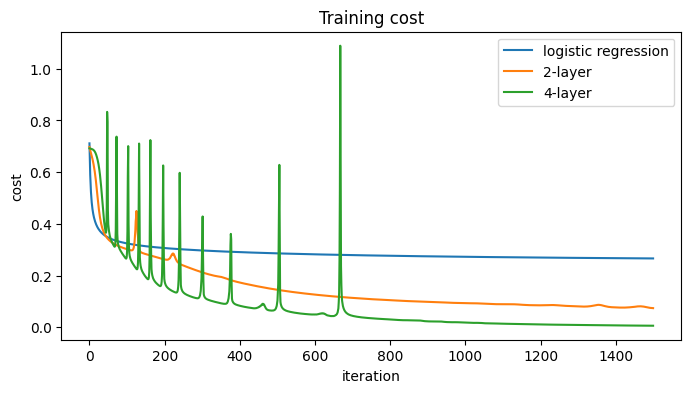

In [6]:
models = {"logistic regression": [784, 1], "2-layer": [784, 7, 1], "4-layer": [784, 20, 7, 5, 1]}
trained, curves = {}, {}
for name, dims in models.items():
    params, costs = L_layer_model(X_train, Y_train, dims, lr=0.2, num_iters=1500)
    trained[name] = params
    curves[name] = costs
    train_acc = accuracy(X_train, Y_train, params)
    dev_acc = accuracy(X_dev, Y_dev, params)
    print(f"{name:20s} final cost {costs[-1]:.4f} | train {100*train_acc:.1f}% | dev {100*dev_acc:.1f}%")

# plot the three cost curves
plt.figure(figsize=(8, 4))
for name, costs in curves.items():
    plt.plot(costs, label=name)
plt.xlabel("iteration")
plt.ylabel("cost")
plt.title("Training cost")
plt.legend()
plt.show()

## Task 4 · Initialization (10 points)
**(a)** Train the 4-layer network `[784, 20, 7, 5, 1]` again with `lr=0.2` and `num_iters=1500`, but initialized with `scale=0.01`, as in the 2-layer networks of Notebook 3. Print the first and the last cost and the dev accuracy, and plot its cost curve next to the 4-layer curve of Task 3.

Expected output (and a figure):
```
scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%
```

**(b)** In a markdown cell: what happened, and why? Link your answer to Exercise 4 of the follow-along.



### Answer:
**What happened.** With `scale=0.01`, the cost stays on a plateau: it goes from 0.6931 to only 0.6923 in 1500 iterations, and the curve is a flat line at $\log 2 \approx 0.693$. This is the cost of a network that outputs about 0.5 for every image. The dev accuracy is 51.2%, which is chance level. The same architecture with the default initialization leaves this plateau within about 50 iterations and reaches a cost near 0.006 and about 96.6% dev accuracy.

**Why.**

1. **The signal vanishes in the forward pass.** Each layer multiplies its input by weights of size about 0.01 and then applies ReLU, so the values get smaller at every layer. By the last layer, $Z^{(4)}$ is almost 0, so $a^{(4)} = \sigma(Z^{(4)})$ is about 0.5 for every image. The output carries no information about the input.

2. **The gradients vanish in the backward pass.** Going back, the gradient is multiplied at each layer by a matrix with entries of about 0.01, so $dW^{(1)}$, $dW^{(2)}$ and $dW^{(3)}$ are tiny. The output-layer gradient $dW^{(4)} = \frac{1}{m} A^{(3)T} (A^{(4)} - Y)$ is also tiny, because $A^{(3)}$ is almost 0. With `lr=0.2` the updates are too small to leave the plateau, so the cost decreases by only about 0.0008 in 1500 iterations.

3. **Link to Exercise 4 of the follow-along.** The follow-along explains that a scale of 0.01 is enough for a 2-layer network, but that deeper networks need $\sqrt{1/n^{(l-1)}}$ so that the values of $Z$ keep a reasonable size from layer to layer. With 0.01 in a 4-layer network, $Z$ shrinks at every layer, the output is about 0.5 for every image, and the gradients vanish, so the cost stays at $\log 2$. The default scale adapts to the number of inputs of each layer, which avoids this.

**Conclusion.** The initialization scale matters more as the network gets deeper. A bad scale does not make training unstable: the network starts in a region where the gradients are almost zero, so it hardly learns.

scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%


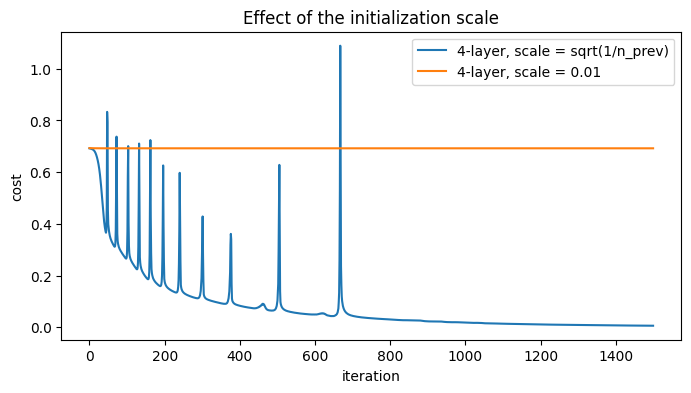

In [7]:
# (a) train with scale=0.01, print the first and last cost and the dev accuracy, plot both curves
dims = [784, 20, 7, 5, 1]
params_small, costs_small = L_layer_model(X_train, Y_train, dims, lr=0.2, num_iters=1500, scale=0.01)
dev_acc_small = accuracy(X_dev, Y_dev, params_small)
print(f"scale 0.01 | first cost {costs_small[0]:.4f} | last cost {costs_small[-1]:.4f} | dev {100*dev_acc_small:.1f}%")

# plot both curves (curves["4-layer"] comes from Task 3)
plt.figure(figsize=(8, 4))
plt.plot(curves["4-layer"], label="4-layer, scale = sqrt(1/n_prev)")
plt.plot(costs_small, label="4-layer, scale = 0.01")
plt.xlabel("iteration")
plt.ylabel("cost")
plt.title("Effect of the initialization scale")
plt.legend()
plt.show()

## Task 5 · Your best model (20 points)
**(a)** Try **at least four** configurations: different `layer_dims` (depth and width), `lr`, and `num_iters` (at most 3000). For each one, print the training accuracy and the **dev** accuracy. Aim for **at least 97% on the dev set**.

**(b)** Choose your best configuration **using the dev accuracy only**. Store its parameters in `best_params`.

**(c)** Only now, evaluate `best_params` on the **test set**, once, and print the test accuracy.

**(d)** In a markdown cell: which configuration did you choose and why? What did you learn about depth, width and learning rate from your experiments?

*Hints:* wider hidden layers (64, 128 units) help. A larger learning rate trains faster, but with deep networks `lr=0.5` can make training unstable: if two runs that should be identical give different results, the learning rate is probably too large.

### Answer:
**Chosen configuration.** I chose configuration F: `layer_dims = [784, 128, 64, 1]`, `lr = 0.3`, `num_iters = 2000`. It had the highest dev accuracy (97.7%), ahead of C and E (97.5%) and D (97.4%). I selected it using the dev set only. Its test accuracy, computed once at the end, is 97.6%, very close to the dev accuracy, so the choice did not overfit the dev set.

**What I learned.**

- **Width:** going from 64 to 128 hidden units in a one-hidden-layer network (A to B) improved the dev accuracy from 96.9% to 97.3%, and the training accuracy from 99.2% to 99.7%. A wider layer can represent more, and it also helped on new data. (B also used 2000 iterations instead of 1500, so this comparison is not perfectly controlled.)

- **Depth:** adding a second hidden layer (B to C) gave a small gain, from 97.3% to 97.5% on dev, and the training accuracy reached 100%. A third hidden layer (D) did not help: dev stayed at 97.4%, even with 3000 iterations. Beyond two hidden layers, extra depth only added capacity that the training set did not need.

- **Learning rate:** for the same network, `lr = 0.1` (E), `0.2` (C) and `0.3` (F) all ended at 100% training accuracy and 97.5% to 97.7% on dev, but they did not train in the same way. A larger learning rate decreased the cost faster: after 2000 iterations the cost is 0.0010 for `lr = 0.3` and 0.0019 for `lr = 0.2`, while `lr = 0.1` needed 3000 iterations to reach only 0.0029. The cost curves also show spikes (sudden jumps, as in Task 3) for all three learning rates, mostly in the first 600 iterations. They are the most frequent and the largest for `lr = 0.3` (the highest goes above 1, higher than the initial cost of about 0.69), and there are fewer of them for `lr = 0.1`. In every case training recovered, and after about iteration 600 the curves are smooth. So a larger learning rate trains faster but is less stable.

- **Bias and variance:** every model fits the training set almost perfectly (99.2% to 100%), so bias is not the problem. The gap between training and dev accuracy is about 2.3 to 2.6 points for the best models, which is variance. More capacity and more iterations cannot close this gap, because the model already memorizes the 10,000 training images.

- **Caution:** the dev set has 2,000 images, so 0.1% is only 2 images. The differences between C, D, E and F (97.4% to 97.7%) are small and may be within noise. What is clear is the gain from using 128 units and 2 hidden layers over the logistic regression of Task 3 (89.3%) and the small networks (95.5% to 96.9%).

In [8]:
# (a) several configurations: different depth, width, learning rate, iterations
configs = [
    # (name,                 layer_dims,                  lr,  num_iters)
    ("A: 1 hidden, 64",      [784, 64, 1],                0.2, 1500),
    ("B: 1 hidden, 128",     [784, 128, 1],               0.2, 2000),
    ("C: 2 hidden, 128-64",  [784, 128, 64, 1],           0.2, 2000),
    ("D: 3 hidden, 128-64-32", [784, 128, 64, 32, 1],     0.2, 3000),
    ("E: like C, lr 0.1",    [784, 128, 64, 1],           0.1, 3000),
    ("F: like C, lr 0.3",    [784, 128, 64, 1],           0.3, 2000),
]

results = {}
for name, dims, lr, iters in configs:
    params, costs = L_layer_model(X_train, Y_train, dims, lr=lr, num_iters=iters)
    train_acc = accuracy(X_train, Y_train, params)
    dev_acc = accuracy(X_dev, Y_dev, params)
    results[name] = {"params": params, "costs": costs, "train": train_acc, "dev": dev_acc}
    print(f"{name:26s} lr {lr:<4} iters {iters:<5} | final cost {costs[-1]:.4f} | train {100*train_acc:.1f}% | dev {100*dev_acc:.1f}%")

# (b) choose on the dev accuracy ONLY
best_name = max(results, key=lambda k: results[k]["dev"])
best_params = results[best_name]["params"]
print(f"\nBest configuration on dev: {best_name} (dev {100*results[best_name]['dev']:.1f}%)")

# (c) test accuracy of best_params, once
test_acc = accuracy(X_test, Y_test, best_params)
print(f"Test accuracy of the chosen model: {100*test_acc:.1f}%")

A: 1 hidden, 64            lr 0.2  iters 1500  | final cost 0.0373 | train 99.2% | dev 96.9%
B: 1 hidden, 128           lr 0.2  iters 2000  | final cost 0.0210 | train 99.7% | dev 97.3%
C: 2 hidden, 128-64        lr 0.2  iters 2000  | final cost 0.0019 | train 100.0% | dev 97.5%
D: 3 hidden, 128-64-32     lr 0.2  iters 3000  | final cost 0.0002 | train 100.0% | dev 97.4%
E: like C, lr 0.1          lr 0.1  iters 3000  | final cost 0.0029 | train 100.0% | dev 97.5%
F: like C, lr 0.3          lr 0.3  iters 2000  | final cost 0.0010 | train 100.0% | dev 97.7%

Best configuration on dev: F: like C, lr 0.3 (dev 97.7%)
Test accuracy of the chosen model: 97.6%


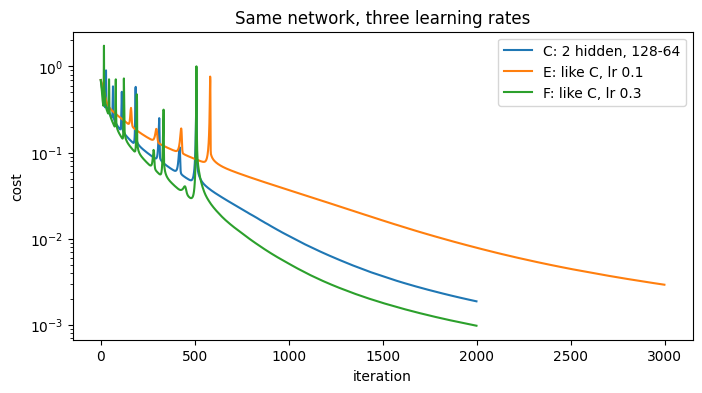

In [9]:
plt.figure(figsize=(8, 4))
for name in ["C: 2 hidden, 128-64", "E: like C, lr 0.1", "F: like C, lr 0.3"]:
    plt.plot(results[name]["costs"], label=name)
plt.xlabel("iteration")
plt.ylabel("cost")
plt.yscale("log")        # the costs go down to about 0.001, a log scale shows spikes at any level
plt.title("Same network, three learning rates")
plt.legend()
plt.show()

## Task 6 · Error analysis (25 points)
Use `best_params` on the test set.

**(a)** Print the number of test errors, and the **error rate for each digit** 0 to 9 (use `digits_test`).

**(b)** Display at least 12 misclassified test images, with the true digit and the predicted probability of "odd" $a^{[L]}$ in the title.

**(c)** In a markdown cell: which digits are hardest? Looking at the images, what do the errors have in common? Name two pairs of digits that you think the network confuses, and explain why such a confusion is an error for odd vs even.

### Answer:

**Hardest digits.** The model makes 235 errors on the 10,000 test images (2.35%), so the test accuracy is 97.65%. The digits with the highest error rates are 9 (3.8%), 8 (3.7%), 5 (3.4%) and 4 (3.1%). The easiest are 0 and 6 (1.1% each) and 1 (1.2%). The hardest digits are the ones whose handwritten shape is the most variable or the closest to a digit of the other parity.

**What the errors have in common.** In the 12 misclassified images, almost all of the digits are written in an unusual or ambiguous way: a 9 with an open top that looks like a 4, a 5 with a closed, rounded bottom that looks like a 6, a 2 written with a straight stem like a 7, and a 7 with a curved top or a crossbar. Many of the errors are not confident (p(odd) between 0.14 and 0.72 in most of the images), which means the network hesitates on these images. A few are confident and wrong: a 5 with p(odd) = 0.00, a 5 with p(odd) = 0.02, a 9 with p(odd) = 0.03 and a 2 with p(odd) = 0.95. Five of the 12 images are 9s, and three are 5s, which matches their high error rates.

**Confused pairs.** The network only outputs p(odd), so I infer the confusions from the shape of the images and not from a 10-class prediction.
1. **4 and 9.** Two of the misclassified 9s (p(odd) = 0.38 and 0.28) have an open top and a vertical stroke, so they look like a 4. The error rate of 4 itself is also high (3.1%). A 4 is even and a 9 is odd, so mixing them up flips the label.
2. **5 and 6.** Two misclassified 5s have a large rounded bottom and a detached top bar, so they look like a 6, and one misclassified 6 (p(odd) = 0.72) has a long thin top stroke. A 5 is odd and a 6 is even, so the label flips.
A third pair is **2 and 7**: a 2 written with a straight stem got p(odd) = 0.95 (predicted odd), and two 7s got p(odd) of 0.31 and 0.14 (predicted even). Again, one is even and the other odd.

Confusing two digits of the same parity (for example 3 and 5, or 7 and 9) is not an error for this task, which is why the odd/even error rate (2.35%) is lower than what a 10-class digit classifier would make on the same digits.

test errors: 235 out of 10000 (2.35%)

digit 0:  980 images | errors  11 | error rate 1.1%
digit 1: 1135 images | errors  14 | error rate 1.2%
digit 2: 1032 images | errors  16 | error rate 1.6%
digit 3: 1010 images | errors  21 | error rate 2.1%
digit 4:  982 images | errors  30 | error rate 3.1%
digit 5:  892 images | errors  30 | error rate 3.4%
digit 6:  958 images | errors  11 | error rate 1.1%
digit 7: 1028 images | errors  28 | error rate 2.7%
digit 8:  974 images | errors  36 | error rate 3.7%
digit 9: 1009 images | errors  38 | error rate 3.8%


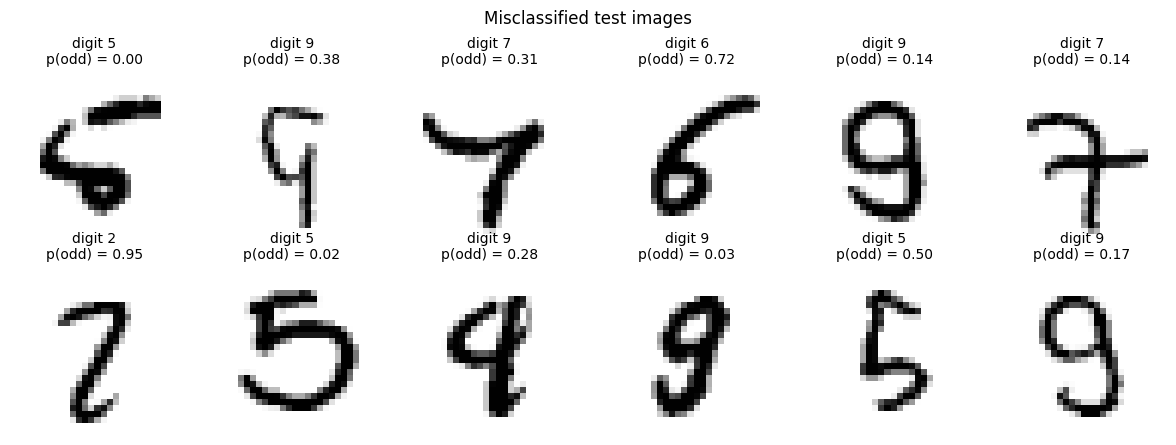

In [10]:
# Predictions of the chosen model on the test set
AL_test, _ = L_model_forward(X_test, best_params)
preds = (AL_test > 0.5).float()
wrong = (preds != Y_test).flatten()          # True where the model is wrong

# (a) number of errors, error rate per digit
print(f"test errors: {wrong.sum().item()} out of {len(Y_test)} ({100*wrong.float().mean().item():.2f}%)\n")
for d in range(10):
    mask = (digits_test == d)
    n_err = wrong[mask].sum().item()
    rate = wrong[mask].float().mean().item()
    print(f"digit {d}: {mask.sum().item():4d} images | errors {n_err:3d} | error rate {100*rate:.1f}%")

# (b) 12 misclassified test images: true digit and p(odd)
wrong_idx = torch.where(wrong)[0][:12]
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.flatten(), wrong_idx):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"digit {digits_test[i].item()}\np(odd) = {AL_test[i].item():.2f}", fontsize=10)
    ax.axis("off")
plt.suptitle("Misclassified test images")
plt.tight_layout()
plt.show()